# Hard threshold cycle

Frozen actions can each be contractions while a threshold rule that chooses among them produces a cycle. The running example is $\rho=1/2$, $\beta=1$.

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from dynafront.certificates import hard_cycle_scores, tau_c, two_step_hard_multiplier
from dynafront.dynamics import simulate_scalar
from dynafront.seeds import MASTER_SEED

rho, beta = 0.5, 1.0
t = tau_c(rho, beta)
zp, zm = hard_cycle_scores(rho, beta)
print("master_seed", MASTER_SEED)
print("tau_c", t)
print("orbit", zp, zm)
print("two-step factor", two_step_hard_multiplier(rho))

master_seed 20260821
tau_c 0.6666666666666666
orbit 0.6666666666666666 -0.6666666666666666
two-step factor 0.25


Each frozen policy $a\equiv\pm 1$ is the contraction $z\mapsto \rho z \mp \beta$, with unique fixed point $\mp\beta/(1-\rho)$. Those points lie on opposite sides of the threshold $0$, so a sign rule cannot sit at either of them.

In [2]:
def frozen(z0, a, n=40):
    z = np.empty(n + 1)
    z[0] = z0
    for k in range(n):
        z[k + 1] = rho * z[k] - beta * a
    return z

z_plus = frozen(2.5, +1)
z_minus = frozen(-2.5, -1)
z_hard, a_hard = simulate_scalar(np.array([2.5, -2.5]), rho, 40, "hard", beta=beta)
print("frozen +1 terminal", z_plus[-1], "fixed point", -beta / (1 - rho))
print("frozen -1 terminal", z_minus[-1], "fixed point", beta / (1 - rho))
print("hard terminals", z_hard[-1])

frozen +1 terminal -1.9999999999959073 fixed point -2.0
frozen -1 terminal 1.9999999999959073 fixed point 2.0
hard terminals [-0.66666667  0.66666667]


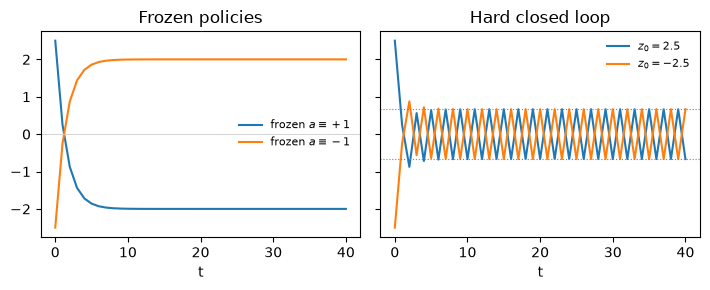

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(7.2, 3.0), sharey=True)
axes[0].plot(z_plus, label=r"frozen $a\equiv+1$")
axes[0].plot(z_minus, label=r"frozen $a\equiv-1$")
axes[0].axhline(0, color="0.8", lw=0.6)
axes[0].set_title("Frozen policies")
axes[0].set_xlabel("t")
axes[0].legend(frameon=False, fontsize=8)
axes[1].plot(z_hard[:, 0], label=r"$z_0=2.5$")
axes[1].plot(z_hard[:, 1], label=r"$z_0=-2.5$")
axes[1].axhline(t, color="0.5", ls=":", lw=0.8)
axes[1].axhline(-t, color="0.5", ls=":", lw=0.8)
axes[1].set_title("Hard closed loop")
axes[1].set_xlabel("t")
axes[1].legend(frameon=False, fontsize=8)
fig.tight_layout()
plt.show()

The distinction is closed-loop versus frozen-policy stability: each map $z\mapsto\rho z-a\beta$ is a contraction, but the selected sequence of maps is not a single contraction to $0$.

Rerun the corresponding paper family:

```bash
python -m dynafront.cli reproduce --mode paper
```

Family `synthetic_a` is included in that mode.